# 07 Sequence models: what happened

Read this first.

**Question.** Does a model that reads the whole night (CNN + BiGRU) stage sleep better than logistic regression on the same features?

**Setup.** 5 folds split by person: each fold tests 7 people, uses 4 for validation and trains on 24. Both models see the same people. Task: 3 classes, W, NREM and REM.

**Result.**

| model | median per-person macro F1 | pooled kappa | REM recall |
|---|---|---|---|
| logistic regression | 0.410 | 0.171 | 0.426 |
| CNN + BiGRU | 0.455 | 0.293 | 0.003 |

**What it means.**
- Reading the whole night helped a lot with wake versus NREM. Kappa rose from 0.17 to 0.29.
- The BiGRU almost never predicts REM. It found 3 in 1,000 REM epochs.
- Likely cause, not yet tested: the class weighting copied from Tallal 2026 gives REM only about 1.2 times the weight of NREM. Our logistic regression gives it about 7 times.

**Warning about the per-person comparison.** 6 of the 35 people had no REM at all that night. For them, a model that predicts some REM scores 0 for REM and gets penalised; a model that never predicts REM is not. So the per-person gain of the BiGRU (+0.023) is partly a reward for staying silent on REM. Pooled kappa is less affected.

**Fair comparison, only the 29 people who had REM (section 5).**
- Per person, BiGRU minus logreg: median +0.020, 95% interval -0.006 to +0.057, 18 better and 11 worse. The interval now includes 0, so on these 29 the per-person gain is not established.
- On the 6 people without REM: median +0.233, all 6 better. That is where most of the earlier gain came from.
- Pooled kappa on the 29: logreg 0.156, BiGRU 0.270. The wake versus NREM improvement holds.

**BiGRU with balanced class weights (section 6, run 2026-10-24).**
- REM comes back: REM recall 0.352 (logreg 0.426), false REM on NREM 0.317 (logreg 0.349).
- The kappa gain shrinks: 0.227 for all 35 (logreg 0.171, Tallal-weighted BiGRU 0.293).
- On the 29 with REM, per person versus logreg: median +0.036, 95% interval -0.002 to +0.048, 19 better and 10 worse. Borderline.
- Reading: with REM weighted properly, the BiGRU is a little better than logreg at wake and NREM and no better at REM. The 10 features do not carry what is needed to separate REM from NREM; context alone does not fix that.

**Not yet decided (hers).** Add per-second heart rate and activity to the BiGRU (the REM features); stratify the folds; repeat the 5 folds with different shuffles.

---
## About this notebook

Phase 2 of `PLAN.md`: does reading the whole night help?

Folds: 5 folds split by person (`make_person_folds`, 7 test people each, 4 validation people for tuning or early stopping, 24 training). Chosen 2026-10-23 instead of 35 leave-one-out folds, so deep models train 5 times, not 35. Logistic regression is rerun on the same 5 folds, so every comparison is paired person by person. Its C is now tuned inside each fold on that fold's own validation people, which removes the tuning leak of open item 17 for this notebook.

Functions come from `src/evaluation.py` and `src/sequence.py`, both tested.

| section | what |
|---|---|
| 1 | load, folds |
| 2 | logistic regression on the 5 folds (reference) |
| 3 | CNN + BiGRU (Tallal 2026 settings) on our 10 features |
| 4 | comparison |

## 1. Load and folds

Number: test people per fold, and how many of them had no REM that night. Figure: that count per fold. Why it matters: see the warning at the top.

 fold  test people  validation people  training people  test people with no REM that night
    0            7                  4               24                                   0
    1            7                  4               24                                   1
    2            7                  4               24                                   0
    3            7                  4               24                                   3
    4            7                  4               24                                   2
people with no REM, all folds: 6 of 35


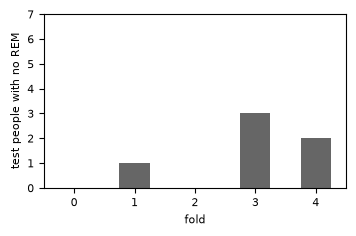

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, f1_score

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from splits import make_person_folds
from evaluation import CLASSES, LABELS, make_xy, run_folds, LogRegFeatures, tune_settings, macro_f1_per_person, rem_rates
from metrics import bootstrap_ci, paired_difference
from sequence import BiGRUSequence, make_sequences

DERIVED = ROOT / "data" / "derived"; FIGS = ROOT / "notebooks" / "figs"
SEED = 20261011
plt.rcParams.update({"font.size": 8})
df = pd.read_csv(DERIVED / "features_all35.csv")
Z = [c for c in df.columns if c.endswith("_z")]
COLS = Z + [c + "_past4" for c in Z] + [c + "_next4" for c in Z]
people = sorted(df.subject.unique())
folds = make_person_folds(people, n_folds=5, n_tune=4, seed=SEED)

# People with no REM that night cannot be scored on REM. That favours a model that never
# predicts REM, so we count them per fold.
had_rem = df.groupby("subject").stage3.agg(lambda s: (s == "REM").any())
comp = pd.DataFrame([{"fold": i, "test people": len(f["test"]), "validation people": len(f["tune"]),
                      "training people": len(f["train"]),
                      "test people with no REM that night": int((~had_rem[f["test"]]).sum())}
                     for i, f in enumerate(folds)])
print(comp.to_string(index=False))
print("people with no REM, all folds:", int((~had_rem).sum()), "of", len(had_rem))
ax = comp.set_index("fold")["test people with no REM that night"].plot.bar(figsize=(3.6, 2.4), rot=0, color="0.4")
ax.set_ylabel("test people with no REM"); ax.set_ylim(0, 7)
plt.tight_layout(); plt.savefig(FIGS / "fig07_folds.png", dpi=150); plt.show()

## 2. Logistic regression on the 5 folds (reference)

Same 30 columns as notebook 06 (10 z features, past4, next4). In each fold, C is chosen from the same 8 values on that fold's validation people only, then the model is refit on the training people and tested once.

In [2]:
X, y, subjects, index = make_xy(df, COLS)
lr_settings = [{"C": float(c)} for c in np.logspace(-3, 2, 8)]
parts, chosen = [], []
for i, f in enumerate(folds):
    t = tune_settings(lambda **s: LogRegFeatures(**s), lr_settings, X, y, subjects, [f], verbose=False)
    C = lr_settings[int(t.iloc[0]["setting"])]["C"]; chosen.append(C)
    p = run_folds(lambda: LogRegFeatures(C=C), X, y, subjects, index, [f], "logreg_5fold", verbose=False)
    parts.append(p.assign(fold=i))
preds_lr5 = pd.concat(parts, ignore_index=True)
preds_lr5.to_csv(DERIVED / "preds_logreg_5fold.csv", index=False)
print("C chosen per fold:", [round(c, 4) for c in chosen])
tab_lr5 = macro_f1_per_person(preds_lr5)
print("logreg, 5 folds: median per-person macro F1", round(tab_lr5.macro_f1.median(), 3),
      "| pooled kappa", round(cohen_kappa_score(preds_lr5.y, preds_lr5.yhat), 3))

C chosen per fold: [3.7276, 3.7276, 0.0268, 100.0, 0.1389]
logreg, 5 folds: median per-person macro F1 0.41 | pooled kappa 0.171


## 3. CNN + BiGRU on our 10 features

Input per epoch: the 10 per-person z-scored features (`_z`) only, not past4 or next4, because the GRU reads the context itself. Missing values: the training median plus a missing flag, so 20 numbers per epoch. Model and training follow Tallal 2026 (see `src/sequence.py`): convolution over neighbouring epochs (64 channels), BiGRU (64 per direction), dropout 0.25; AdamW, lr 0.001, up to 30 passes, effective-number weighted loss; the pass with the best validation macro F1 is kept. One whole night per sequence. HEAVY: about a minute per fold on CPU.

In [3]:
Xz, yz, sz, iz = make_xy(df, Z)
ep = df.loc[iz, "epoch"].to_numpy()
parts, info = [], []
t0 = time.time()
for i, f in enumerate(folds):
    tr = np.isin(sz, f["train"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        med = np.nanmedian(Xz[tr], axis=0)
    med = np.where(np.isnan(med), 0.0, med)
    seq = {s["subject"]: s for s in make_sequences(Xz, yz, sz, iz, ep, med)}
    m = BiGRUSequence().fit([seq[s] for s in f["train"]], [seq[s] for s in f["tune"]])
    test = [seq[s] for s in f["test"]]
    for s, yh in zip(test, m.predict(test)):
        parts.append(pd.DataFrame({"subject": s["subject"], "row": s["row"], "y": s["y"], "yhat": yh,
                                   "fold": i, "model": "bigru"}))
    info.append({"fold": i, "best_pass": m.best_epoch_, "val_macro_f1": round(m.best_val_f1_, 3)})
    print(f"fold {i + 1}/5 done, {time.time() - t0:.0f}s", end="\r")
preds_gru = pd.concat(parts, ignore_index=True)
preds_gru.to_csv(DERIVED / "preds_bigru_5fold.csv", index=False)
print(); print(pd.DataFrame(info).to_string(index=False))

fold 5/5 done, 145s
 fold  best_pass  val_macro_f1
    0         28         0.470
    1         19         0.554
    2          7         0.389
    3         11         0.417
    4         14         0.382


## 4. Comparison

Same people, same folds. Number: the paired per-person difference in macro F1 (BiGRU minus logreg), median and 95% interval.

Figure: one dot per person. Across: that person's score with logistic regression. Up: with the BiGRU. Above the dashed line, the BiGRU did better for that person; below it, worse. Filled dots: people who had REM that night. Open red dots: people with no REM, who cannot be scored on REM (see the warning at the top).

               median_macro_f1  kappa_pooled  rem_f1  rem_recall  false_rem_on_nrem
model                                                                              
logreg 5-fold            0.410         0.171   0.193       0.426              0.349
CNN+BiGRU                0.455         0.293   0.006       0.003              0.001



per person, BiGRU minus logreg: median +0.023  95% CI [+0.002, +0.125]  better 24 / worse 11


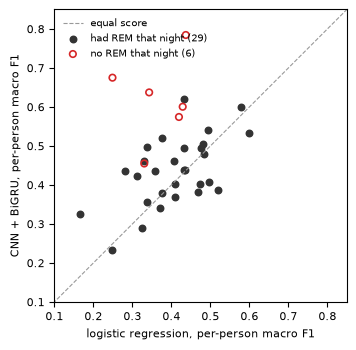

In [4]:
def summary(name, p):
    t = macro_f1_per_person(p); rr, fr = rem_rates(p)
    return {"model": name, "median_macro_f1": t.macro_f1.median(), "kappa_pooled": cohen_kappa_score(p.y, p.yhat),
            "rem_f1": f1_score(p.y, p.yhat, labels=[2], average="macro"), "rem_recall": rr, "false_rem_on_nrem": fr}

tab_gru = macro_f1_per_person(preds_gru)
print(pd.DataFrame([summary("logreg 5-fold", preds_lr5), summary("CNN+BiGRU", preds_gru)]).set_index("model").round(3).to_string())
d = paired_difference(tab_gru.macro_f1, tab_lr5.macro_f1)
print(f"\nper person, BiGRU minus logreg: median {d['median']:+.3f}  95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  "
      f"better {int((tab_gru.macro_f1 - tab_lr5.macro_f1 > 0).sum())} / worse {int((tab_gru.macro_f1 - tab_lr5.macro_f1 < 0).sum())}")

fig, ax = plt.subplots(figsize=(3.6, 3.6))
both = pd.concat([tab_lr5.macro_f1.rename("logreg"), tab_gru.macro_f1.rename("bigru")], axis=1).dropna()
rem = both.index.isin(had_rem[had_rem].index)
ax.plot([0, 1], [0, 1], color="0.6", lw=0.8, ls="--", label="equal score")
ax.scatter(both.logreg[rem], both.bigru[rem], s=22, color="0.2", label=f"had REM that night ({rem.sum()})")
ax.scatter(both.logreg[~rem], both.bigru[~rem], s=22, facecolor="none", edgecolor="tab:red", lw=1.2,
           label=f"no REM that night ({(~rem).sum()})")
ax.set_xlabel("logistic regression, per-person macro F1"); ax.set_ylabel("CNN + BiGRU, per-person macro F1")
ax.set_xlim(0.1, 0.85); ax.set_ylim(0.1, 0.85); ax.set_aspect("equal")
ax.legend(frameon=False, fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig(FIGS / "fig07_bigru_vs_logreg.png", dpi=150); plt.show()

## 5. Fair comparison: only the 29 people who had REM

Why: a person with no REM that night cannot be scored on REM, which favours a model that never predicts REM (warning at the top). Here both models are judged only on people where REM was possible. No retraining; same saved predictions. Number: the paired per-person difference on these 29. Figure: the filled dots in the section 4 figure.

In [5]:
with_rem = had_rem[had_rem].index
p_lr, p_gru = preds_lr5[preds_lr5.subject.isin(with_rem)], preds_gru[preds_gru.subject.isin(with_rem)]
print("people:", p_lr.subject.nunique(), "| epochs:", len(p_lr))
print(pd.DataFrame([summary("logreg 5-fold", p_lr), summary("CNN+BiGRU", p_gru)]).set_index("model").round(3).to_string())
t_lr, t_gru = macro_f1_per_person(p_lr), macro_f1_per_person(p_gru)
d = paired_difference(t_gru.macro_f1, t_lr.macro_f1)
diff = t_gru.macro_f1 - t_lr.macro_f1
print(f"\nper person (29 with REM), BiGRU minus logreg: median {d['median']:+.3f}  95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  "
      f"better {int((diff > 0).sum())} / worse {int((diff < 0).sum())}")
no_rem = had_rem[~had_rem].index
dn = (macro_f1_per_person(preds_gru[preds_gru.subject.isin(no_rem)]).macro_f1
      - macro_f1_per_person(preds_lr5[preds_lr5.subject.isin(no_rem)]).macro_f1)
print(f"for comparison, the 6 without REM: median {dn.median():+.3f}, better {int((dn > 0).sum())} / worse {int((dn < 0).sum())}")



people: 29 | epochs: 23435
               median_macro_f1  kappa_pooled  rem_f1  rem_recall  false_rem_on_nrem
model                                                                              
logreg 5-fold            0.410         0.156   0.217       0.426              0.354
CNN+BiGRU                0.436         0.270   0.006       0.003              0.001



per person (29 with REM), BiGRU minus logreg: median +0.020  95% CI [-0.006, +0.057]  better 18 / worse 11
for comparison, the 6 without REM: median +0.233, better 6 / worse 0


## 6. BiGRU with balanced class weights (the REM fix)

One change from section 3: the loss weights each stage by how rare it is, the same rule as our logistic regression (`class_weight="balanced"`), instead of Tallal's effective-number weights. With our class sizes that gives REM about 7 times the weight of NREM instead of about 1.2 times. Everything else is identical: same folds, same 20 inputs per epoch, same architecture and settings.

Numbers: the comparison table for all 35 people and for the 29 with REM. Figure: two tables of shares. Each row is a true stage; each cell says what share of that stage's epochs the model called W, NREM or REM. A perfect model has 100% on the diagonal.

trained in 147s
 fold  best_pass  val_macro_f1
    0         29         0.480
    1         13         0.499
    2         13         0.433
    3         26         0.474
    4         30         0.432
                                     median_macro_f1  kappa_pooled  rem_f1  rem_recall  false_rem_on_nrem
people      model                                                                                        
all 35      logreg                             0.410         0.171   0.193       0.426              0.349
            BiGRU, Tallal weights              0.455         0.293   0.006       0.003              0.001
            BiGRU, balanced weights            0.426         0.227   0.178       0.352              0.317
29 with REM logreg                             0.410         0.156   0.217       0.426              0.354
            BiGRU, Tallal weights              0.436         0.270   0.006       0.003              0.001
            BiGRU, balanced weights            0.420    

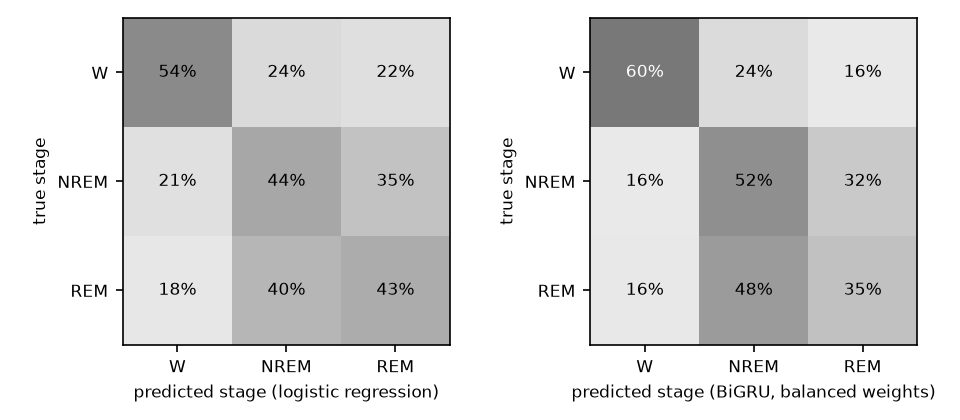

In [ ]:
parts, info = [], []
t0 = time.time()
for i, f in enumerate(folds):
    tr = np.isin(sz, f["train"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        med = np.nanmedian(Xz[tr], axis=0)
    med = np.where(np.isnan(med), 0.0, med)
    seq = {s["subject"]: s for s in make_sequences(Xz, yz, sz, iz, ep, med)}
    m = BiGRUSequence(weighting="balanced").fit([seq[s] for s in f["train"]], [seq[s] for s in f["tune"]])
    test = [seq[s] for s in f["test"]]
    for s, yh in zip(test, m.predict(test)):
        parts.append(pd.DataFrame({"subject": s["subject"], "row": s["row"], "y": s["y"], "yhat": yh,
                                   "fold": i, "model": "bigru_balanced"}))
    info.append({"fold": i, "best_pass": m.best_epoch_, "val_macro_f1": round(m.best_val_f1_, 3)})
preds_grub = pd.concat(parts, ignore_index=True)
preds_grub.to_csv(DERIVED / "preds_bigru_balanced_5fold.csv", index=False)
print(f"trained in {time.time() - t0:.0f}s"); print(pd.DataFrame(info).to_string(index=False))

rows = []
for who, keep in [("all 35", people), ("29 with REM", list(with_rem))]:
    for name, p in [("logreg", preds_lr5), ("BiGRU, Tallal weights", preds_gru), ("BiGRU, balanced weights", preds_grub)]:
        rows.append({"people": who, **summary(name, p[p.subject.isin(keep)])})
print(pd.DataFrame(rows).set_index(["people", "model"]).round(3).to_string())
t_b = macro_f1_per_person(preds_grub[preds_grub.subject.isin(with_rem)])
t_l = macro_f1_per_person(preds_lr5[preds_lr5.subject.isin(with_rem)])
d = paired_difference(t_b.macro_f1, t_l.macro_f1); diff = t_b.macro_f1 - t_l.macro_f1
print(f"\n29 with REM, balanced BiGRU minus logreg: median {d['median']:+.3f}  95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  "
      f"better {int((diff > 0).sum())} / worse {int((diff < 0).sum())}")

from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.8))
for ax, (name, p) in zip(axes, [("logistic regression", preds_lr5), ("BiGRU, balanced weights", preds_grub)]):
    cm = confusion_matrix(p.y, p.yhat, labels=LABELS, normalize="true") * 100
    ax.imshow(cm, cmap="Greys", vmin=0, vmax=100)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{cm[r, c]:.0f}%", ha="center", va="center", color="white" if cm[r, c] > 55 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel(f"predicted stage ({name})"); ax.set_ylabel("true stage")
plt.tight_layout(); plt.savefig(FIGS / "fig07_confusion_logreg_vs_bigru_balanced.png", dpi=150); plt.show()